| Inicio | Anterior | Siguiente |
| --- | --- | --- |
| [🏠](../README.md) | [⏪](../9_METODOS_NUMERICOS_PARA_PDE/9_2_Finite_Element_Method.ipynb) | [⏩](../9_METODOS_NUMERICOS_PARA_PDE/9_4_Spectral_Methods.ipynb) |

# 9.3 Finite Volume Method: conservar mediante flujos de interfaz

Los volúmenes finitos integran una ley de conservación en cada celda. La incógnita representa un promedio, y las celdas intercambian cantidades mediante un flujo compartido en sus interfaces. Construiremos advección periódica upwind, difusión conservativa y una ley no lineal de Burgers con flujo Rusanov.

Objetivos: derivar un balance de celda, verificar conservación global, estudiar difusión numérica y CFL, reconocer promedios frente a valores puntuales y tratar cambios de conductividad con promedios armónicos.

Este cuaderno se ejecuta de arriba abajo y genera todos los datos localmente. Los ejemplos son unidimensionales salvo un experimento 2D pequeño. Se necesitan cálculo multivariable, ecuaciones diferenciales y álgebra lineal. La sencillez de la geometría permite concentrarse en formulación, error, estabilidad y propiedades físicas.

## 1. De la PDE al balance de un volumen

Para $u_t+F(u)_x=s$, integra en la celda $C_i=[x_{i-1/2},x_{i+1/2}]$:
$$\frac{d}{dt}\bar u_i=-\frac{F_{i+1/2}-F_{i-1/2}}{\Delta x_i}+\bar s_i,$$
$$\bar u_i=\frac1{\Delta x_i}\int_{C_i}u(x)\,dx.$$
La conservación se obtiene si la interfaz compartida utiliza **un único flujo** para las dos celdas. Lo que sale de una entra en la otra. En dominio periódico y sin fuentes, todos los flujos se cancelan al sumar.

Las incógnitas son promedios, no valores exactos en centros. Para campos suaves difieren por $O(\Delta x^2)$, pero cerca de discontinuidades la diferencia es decisiva. Una validación adecuada compara promedios exactos con promedios numéricos.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import sparse
from scipy.sparse.linalg import spsolve
from scipy.optimize import minimize_scalar
plt.rcParams.update({"figure.figsize":(9,4),"axes.grid":True,"font.size":11})
np.set_printoptions(precision=6,suppress=True)

## 2. Advección y flujo upwind

Para velocidad constante positiva, el flujo físico es $F=cu$ y la interfaz recibe información de la izquierda:
$$\widehat F_{i+1/2}=c\bar u_i.$$
Euler temporal da $\bar u_i^{n+1}=\bar u_i^n-C(\bar u_i^n-\bar u_{i-1}^n)$ con $C=c\Delta t/\Delta x$. En malla uniforme coincide algebraicamente con FDM upwind, pero la interpretación del estado y del balance es diferente.

Para $c<0$, se usa el estado derecho. La fórmula general es $\widehat F=c^+u_L+c^-u_R$, con $c^+=\max(c,0)$ y $c^-=\min(c,0)$.

Máxima deriva de masa: 4.440892098500626e-16


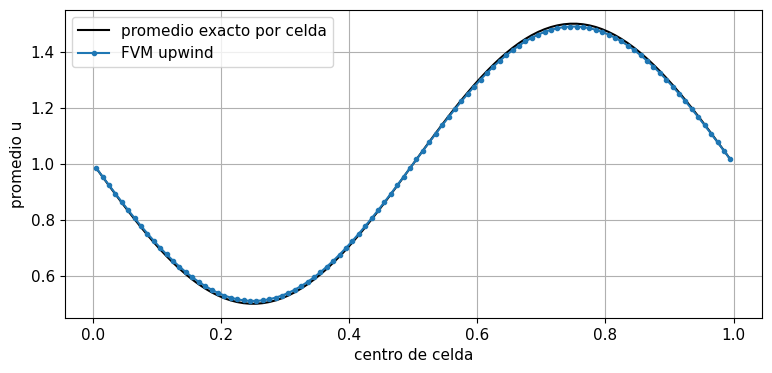

In [2]:
def advect_fv(initial,T,c_speed,cfl=0.8):
    u=np.array(initial,dtype=float).copy(); n=len(u); dx=1/n
    steps=max(1,int(np.ceil(T*abs(c_speed)/(cfl*dx))))
    dt=T/steps; mass=[dx*u.sum()]
    for _ in range(steps):
        right=np.roll(u,-1)
        flux=max(c_speed,0)*u+min(c_speed,0)*right
        u -= dt/dx*(flux-np.roll(flux,1))
        mass.append(dx*u.sum())
    return u,np.array(mass),dt

n=100; dx=1/n; x=(np.arange(n)+0.5)*dx
u0=1+0.5*np.sin(2*np.pi*x)*np.sinc(dx)
T,c_speed=0.5,1.
u,mass,dt=advect_fv(u0,T,c_speed)
exact=1+0.5*np.sin(2*np.pi*(x-c_speed*T))*np.sinc(dx)
plt.plot(x,exact,"k",label="promedio exacto por celda")
plt.plot(x,u,"o-",markersize=3,label="FVM upwind")
plt.xlabel("centro de celda"); plt.ylabel("promedio u"); plt.legend(); plt.show()
print("Máxima deriva de masa:",np.max(abs(mass-mass[0])))

**Interpretación del experimento.** El factor sinc incorpora la integración exacta del seno sobre cada celda. La masa se conserva hasta redondeo, mientras la amplitud se reduce por difusión numérica. Ambos diagnósticos deben reportarse.

## 3. CFL, positividad y monotonía

Para $0\le C\le1$, el nuevo estado es $(1-C)\bar u_i+C\bar u_{i-1}$. Los pesos no negativos preservan positividad y no crean un nuevo máximo local. Con $C>1$ pierde esa propiedad y puede hacerse inestable.

La condición CFL compara la distancia física recorrida en un paso con el tamaño de celda. Una condición CFL necesaria no garantiza estabilidad de cualquier esquema; debe combinarse con el flujo y el método temporal específicos.

C=0.300, min=1.48e-29, max=0.983, masa=0.2000
C=0.800, min=0, max=1, masa=0.2000
C=1.000, min=0, max=1, masa=0.2000


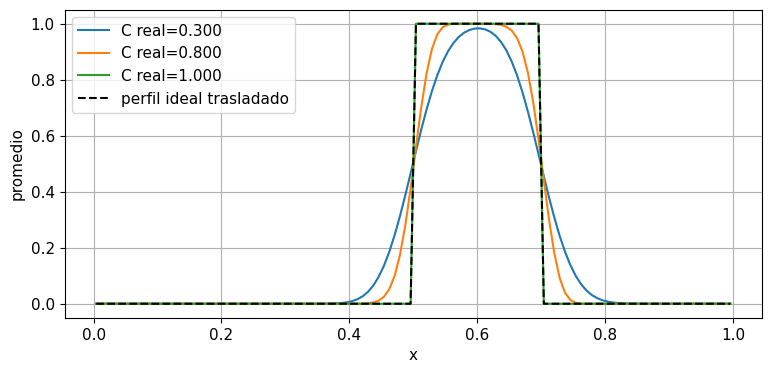

In [3]:
n=120; dx=1/n; x=(np.arange(n)+0.5)*dx
u0=((x>=0.2)&(x<=0.4)).astype(float)
T=0.3
for cfl in [0.3,0.8,1.]:
    u,mass,dt=advect_fv(u0,T,1.,cfl)
    plt.plot(x,u,label=f"C real={dt/dx:.3f}")
    print(f"C={dt/dx:.3f}, min={u.min():.3g}, max={u.max():.3g}, masa={mass[-1]:.4f}")
plt.plot(x,(((x-T)%1>=0.2)&((x-T)%1<=0.4)).astype(float),"k--",label="perfil ideal trasladado")
plt.xlabel("x"); plt.ylabel("promedio"); plt.legend(); plt.show()

**Interpretación del experimento.** El transporte con C=1 desplaza exactamente una celda por paso en este caso periódico, mientras C menor introduce ensanchamiento. La curva ideal usa un valor representativo en centros; en las celdas que cruzan un salto debe compararse el promedio integrado.

## 4. Convergencia para una solución suave

Para la señal sinusoidal podemos evaluar promedios exactos en cada malla. Medimos norma $L^1$ discreta $\sum_i\Delta x|\bar u_i-\bar u_i^*|$. Usando CFL fijo, $\Delta t=O(\Delta x)$ y el error combinado de upwind es de primer orden.

Órdenes observados: [0.967836 1.067895 1.037534 0.996441]


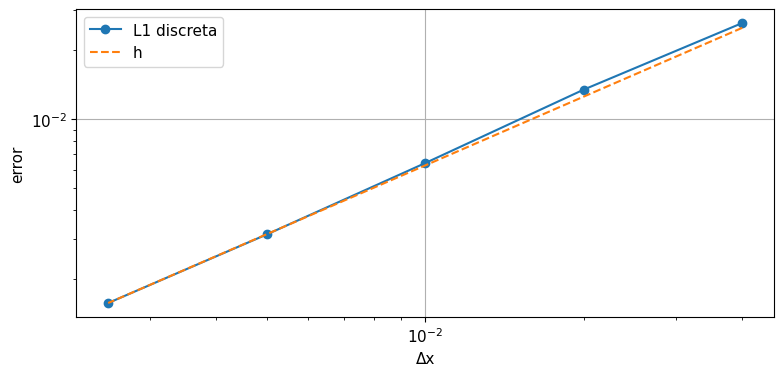

In [4]:
ns=np.array([25,50,100,200,400]); errors=[]
for n in ns:
    dx=1/n; x=(np.arange(n)+0.5)*dx
    u0=1+0.5*np.sin(2*np.pi*x)*np.sinc(dx)
    u,_,dt=advect_fv(u0,0.5,1.,0.8)
    exact=1+0.5*np.sin(2*np.pi*(x-0.5))*np.sinc(dx)
    errors.append(dx*np.sum(abs(u-exact)))
errors=np.array(errors)
print("Órdenes observados:",np.log2(errors[:-1]/errors[1:]))
plt.loglog(1/ns,errors,"o-",label="L1 discreta")
plt.loglog(1/ns,errors[-1]*ns[-1]/ns,"--",label="h")
plt.xlabel("Δx"); plt.ylabel("error"); plt.legend(); plt.show()

**Interpretación del experimento.** Se espera una tasa cercana a uno, con pequeñas variaciones porque el paso final se ajusta al horizonte. Para una discontinuidad, otras tasas y normas pueden dominar; no uses este resultado suave como garantía de precisión de un shock.

## 5. Reconstrucción y limitadores

El upwind básico usa un valor constante por celda. Para orden mayor se reconstruye $u_i(x)=\bar u_i+\sigma_i(x-x_i)$ y se evalúan estados de interfaz. Una pendiente central sin control puede generar sobrepasos cerca de saltos.

Un limitador minmod define $\sigma_i=\operatorname{minmod}((\bar u_i-\bar u_{i-1})/h,(\bar u_{i+1}-\bar u_i)/h)$, donde devuelve el menor módulo con signo común y cero si difieren los signos. Reduce a primer orden donde detecta un extremo o discontinuidad. Un flujo de alto orden espacial debe combinarse con un integrador temporal de orden compatible.

La variación total discreta $TV(u)=\sum_i|u_{i+1}-u_i|$ cuantifica oscilaciones. Esquemas TVD evitan aumentarla bajo sus condiciones, pero no eliminan toda difusión. En este cuaderno mantenemos reconstrucción constante para aislar el balance y la CFL.

In [5]:
def minmod(a,b):
    return np.where(a*b>0,np.sign(a)*np.minimum(abs(a),abs(b)),0.)

n=80; dx=1/n; x=(np.arange(n)+0.5)*dx
u0=((x>0.2)&(x<0.5)).astype(float)
slopes=minmod((u0-np.roll(u0,1))/dx,(np.roll(u0,-1)-u0)/dx)
u,_,_=advect_fv(u0,0.3,1.,0.8)
tv=lambda v:np.sum(abs(np.roll(v,-1)-v))
print("TV inicial/final:",tv(u0),tv(u))
print("Máxima pendiente minmod en escalón:",abs(slopes).max())

TV inicial/final: 2.0 1.999999999994448
Máxima pendiente minmod en escalón: 0.0


**Interpretación del experimento.** En un escalón con tramos constantes, minmod anula las pendientes cercanas al salto. El transporte upwind no crea oscilaciones, pero suaviza el frente. TVD y conservación de masa no significan conservar todo detalle del perfil.

## 6. Ley no lineal: Burgers

Burgers inviscida es
$$u_t+\left(\frac{u^2}{2}\right)_x=0.$$
La velocidad característica es $F'(u)=u$: regiones de mayor valor avanzan más rápido. Pueden aparecer shocks, y la solución débil correcta requiere un criterio de entropía.

El flujo Rusanov usa
$$\widehat F(u_L,u_R)=\frac{F(u_L)+F(u_R)}2-\frac a2(u_R-u_L),\qquad a=\max(|u_L|,|u_R|).$$
La segunda parte añade disipación proporcional a la máxima velocidad local. Ajustamos el paso con una CFL basada en $\max|u|$.

Deriva máxima masa: 1.1102230246251565e-16


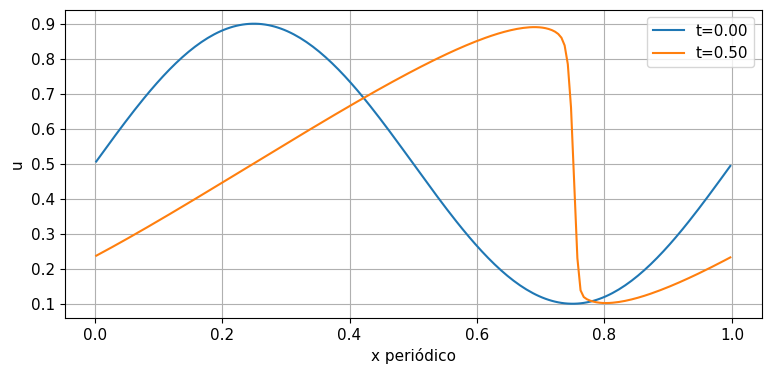

In [6]:
n=200; dx=1/n; x=(np.arange(n)+0.5)*dx
u0=0.5+0.4*np.sin(2*np.pi*x); u=u0.copy(); t=0.; T=0.5
snapshots=[(0.,u.copy())]; masses=[dx*u.sum()]
while t<T:
    speed=max(np.max(abs(u)),1e-12); dt=min(0.45*dx/speed,T-t)
    right=np.roll(u,-1); a=np.maximum(abs(u),abs(right))
    flux=0.25*(u*u+right*right)-0.5*a*(right-u)
    u -= dt/dx*(flux-np.roll(flux,1)); t+=dt; masses.append(dx*u.sum())
snapshots.append((t,u.copy()))
for time,state in snapshots: plt.plot(x,state,label=f"t={time:.2f}")
plt.xlabel("x periódico"); plt.ylabel("u"); plt.legend(); plt.show()
print("Deriva máxima masa:",np.max(abs(np.array(masses)-masses[0])))

**Interpretación del experimento.** El lado descendente del seno se empina porque valores altos alcanzan a los bajos. La disipación del flujo estabiliza el frente. La conservación de masa es comprobable exactamente en la fórmula; la selección de una solución entrópica requiere propiedades adicionales del esquema.

## 7. Difusión como diferencia de flujos

Para $u_t=\alpha u_{xx}$, define flujo $q=-\alpha u_x$. Una aproximación de interfaz es
$$q_{i+1/2}=-\alpha\frac{\bar u_{i+1}-\bar u_i}{h}.$$
El balance $\bar u_i^{n+1}=\bar u_i^n-\Delta t(q_{i+1/2}-q_{i-1/2})/h$ recupera el laplaciano central. En periodicidad conserva masa y disminuye energía con un paso estable.

La forma de flujo facilita controlar conservación incluso con coeficientes espaciales variables. La condición explícita en malla uniforme vuelve a ser $\alpha\Delta t/h^2\le1/2$.

Deriva masa: 2.220446049250313e-16


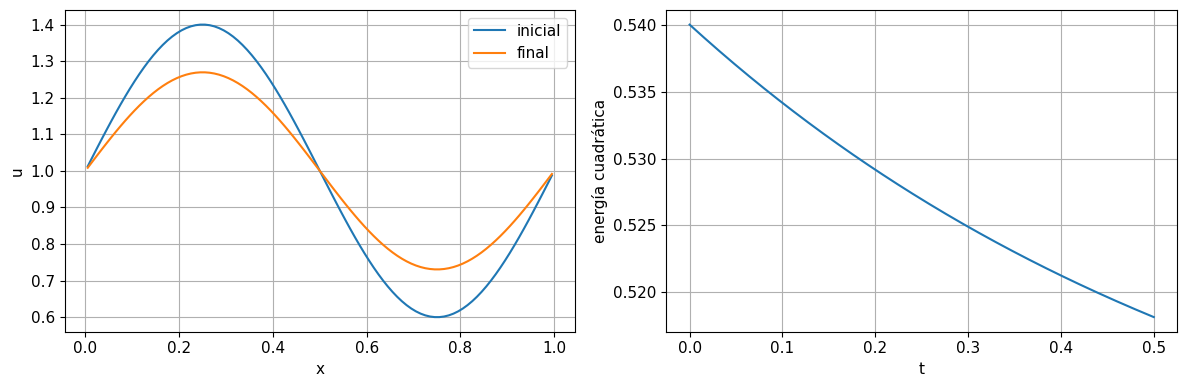

In [7]:
n=100; dx=1/n; x=(np.arange(n)+0.5)*dx; alpha=0.02; T=0.5
u0=1+0.4*np.sin(2*np.pi*x); u=u0.copy()
steps=int(np.ceil(T*alpha/(0.4*dx*dx))); dt=T/steps
energies=[dx*np.sum(u*u)/2]; masses=[dx*u.sum()]
for _ in range(steps):
    flux=-alpha*(np.roll(u,-1)-u)/dx
    u-=dt/dx*(flux-np.roll(flux,1))
    energies.append(dx*np.sum(u*u)/2); masses.append(dx*u.sum())
fig,ax=plt.subplots(1,2,figsize=(12,4))
ax[0].plot(x,u0,label="inicial"); ax[0].plot(x,u,label="final"); ax[0].legend()
ax[0].set(xlabel="x",ylabel="u")
ax[1].plot(np.arange(steps+1)*dt,energies); ax[1].set(xlabel="t",ylabel="energía cuadrática")
plt.tight_layout(); plt.show()
print("Deriva masa:",max(abs(np.array(masses)-masses[0])))

**Interpretación del experimento.** La masa se mantiene y la energía decrece hacia la energía del estado uniforme de igual promedio. Ambas propiedades derivan de la misma estructura de flujos y condiciones de frontera.

## 8. Interfaces materiales y promedio armónico

En difusión estacionaria con conductividad a distinta a cada lado, el flujo atraviesa resistencias en serie. Si las distancias desde centros a la cara son $d_L,d_R$, el coeficiente efectivo es
$$a_f=\frac{d_L+d_R}{d_L/a_L+d_R/a_R}.$$
Para iguales distancias es el promedio armónico $2a_La_R/(a_L+a_R)$. El promedio aritmético puede sobreestimar transporte cuando un material es mucho menos conductor.

En una barra con a=1 en la mitad izquierda y a=10 en la derecha, $u(0)=1$, $u(1)=0$, la resistencia total es $0.5/1+0.5/10=0.55$ y el flujo constante es $q=1/0.55$. La pendiente es mucho mayor en el material menos conductor.

Flujo exacto: 1.8181818181818181 armónico interfaz: 1.8181818181818181 aritmético: 5.5


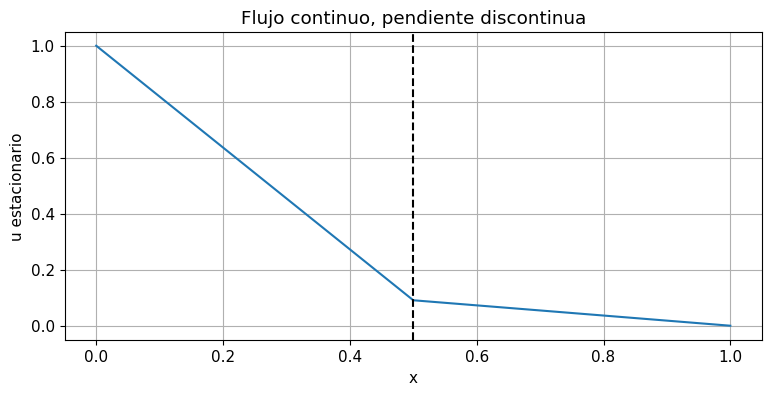

In [8]:
x=np.linspace(0,1,501); flux=1/(0.5+0.5/10)
u=np.where(x<=0.5,1-flux*x,1-flux*0.5-flux*(x-0.5)/10)
plt.plot(x,u); plt.axvline(0.5,color="k",linestyle="--")
plt.xlabel("x"); plt.ylabel("u estacionario"); plt.title("Flujo continuo, pendiente discontinua")
plt.show()
print("Flujo exacto:",flux,"armónico interfaz:",2*1*10/(1+10),"aritmético:",5.5)

**Interpretación del experimento.** La solución es continua mientras cambia su pendiente; el producto a por pendiente preserva el flujo. Suponer una derivada suave en la interfaz sería incompatible con materiales distintos.

## 9. Condiciones de frontera y fuentes

En una frontera abierta, el flujo necesita estados externos compatibles con la dirección de entrada. Para una pared impermeable, el flujo normal es cero. En periodicidad, última y primera celda comparten interfaz. Si cada lado usa un flujo diferente, se pierde conservación.

Una fuente cambia la masa por $\sum_i\Delta x_i\bar s_i$. En equilibrio entre flujo y fuente, una discretización puede no preservar exactamente el estado estacionario; los esquemas bien equilibrados se diseñan para ello. No añadas fuentes sin comprobar el balance correspondiente.

## 10. Errores cerca de shocks

Al aparecer discontinuidades, la derivada clásica deja de existir y se usa una solución débil integral. La posición del shock cumple condiciones de Rankine–Hugoniot; una red suave puede representar un frente ensanchado y obtener una pérdida puntual aparentemente pequeña sin reproducir bien su ubicación.

Para comparar, usa norma L1, balances y posición del frente. Diferenciar un campo discontinuo con fórmulas suaves puede ser engañoso. En PINNs para leyes hiperbólicas, formulaciones integrales, pérdidas entrópicas y estrategias de muestreo requieren especial atención.

## 11. Conservación y aprendizaje de flujos

Una corrección aprendida puede introducirse en el flujo de interfaz y compartirse entre celdas. Entonces la cancelación global se conserva algebraicamente aunque el flujo contenga una red. Aprender directamente un incremento independiente por celda no garantiza ese balance.

La arquitectura conservativa aporta una propiedad exacta, pero todavía hay que controlar estabilidad, positividad y generalización. Un flujo aprendido que conserva masa puede producir shocks equivocados o estados negativos. Evaluar solo error promedio y masa sería insuficiente.

## 12. Verificación, validación y vínculo con SciML

Una **verificación** pregunta si resolvemos correctamente las ecuaciones que elegimos: compara soluciones exactas, realiza refinamiento de malla, mide residual y observa propiedades discretas. Una **validación física** compara el modelo con mediciones independientes y sus incertidumbres. Un método de volúmenes finitos puede estar perfectamente verificado y aun así representar una ley física inadecuada.

Para fabricar una solución conocida, elige $u_*$, sustitúyela en la PDE y deriva la fuente y las fronteras correspondientes. Al ejecutar el solver, compara con $u_*$ en una norma definida. Este método detecta signos, índices y condiciones de frontera mal implementados; no prueba por sí solo desempeño en todo problema.

Si los campos numéricos se usan para entrenar un operador neuronal, documenta malla, paso temporal, condiciones de frontera, precisión del solver y distribución de parámetros. Reserva casos de prueba y compara también resoluciones no vistas. Un modelo aprendido puede reproducir el sesgo de discretización de sus etiquetas; una métrica sobre la misma malla no revela necesariamente ese problema.

Una PINN utiliza residuales de una PDE, pero también necesita satisfacer datos iniciales y de frontera. Un residual pequeño en pocos puntos no garantiza un campo preciso entre ellos. Compara contra una solución numérica refinada, revisa balances y calcula una norma sobre una malla de evaluación independiente. Las distintas formulaciones de residual, fuerte e integral, aportan criterios científicos diferentes.

| Inicio | Anterior | Siguiente |
| --- | --- | --- |
| [🏠](../README.md) | [⏪](../9_METODOS_NUMERICOS_PARA_PDE/9_2_Finite_Element_Method.ipynb) | [⏩](../9_METODOS_NUMERICOS_PARA_PDE/9_4_Spectral_Methods.ipynb) |